# Solar PV tracking options

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

import atlite

## Download cutout data for Portugal

In [2]:
url = (
    "zip+https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)
world = gpd.read_file(url)
portugal = world.query('NAME == "Portugal"')

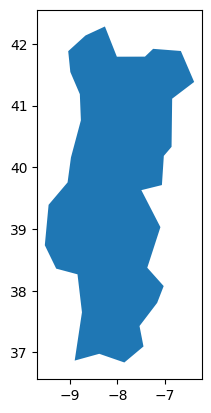

In [3]:
portugal.plot();

In [4]:
cutout = atlite.Cutout(
    path="port-era5-2019-05.nc",
    module="era5",
    bounds=portugal.iloc[0].geometry.bounds,
    time="2019-05",
)

cutout.prepare(["influx", "temperature"])

/home/fabian/vres/py/atlite/atlite/cutout.py:185: UserWarning: Arguments module, bounds, time are ignored, since cutout is already built.
  warn(


<Cutout "port-era5-2019-05">
 x = -9.50 ⟷ -6.50, dx = 0.25
 y = 37.00 ⟷ 42.25, dy = 0.25
 time = 2019-05-01 ⟷ 2019-05-31, dt = H
 module = era5
 prepared_features = ['influx', 'temperature']

## Calculate capacity factors for the three solar PV tracking options

- `tracking=None` for no tracking
- `tracking='horizontal'` for 1-axis horizontal tracking
- `tracking='tilted_horizontal'` for 1-axis horizontal tracking with tilted axis
- `tracking='vertical'` for 1-axis vertical tracking
- `tracking='dual'` for 2-axis tracking

### No tracking

In [5]:
cf_pv_0axis = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking=None,
    per_unit=True,
)

round(cf_pv_0axis.to_pandas().mean().mean(), 3)

0.233

### 1-axis horizontal tracking

In [6]:
cf_pv_1axis_h = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking="horizontal",
    per_unit=True,
)

round(cf_pv_1axis_h.to_pandas().mean().mean(), 3)

0.321

### 1-axis tilted-panel horizontal tracking

In [7]:
cf_pv_1axis_th = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking="tilted_horizontal",
    per_unit=True,
)

round(cf_pv_1axis_th.to_pandas().mean().mean(), 3)

0.322

### 1-axis vertical tracking

In [8]:
cf_pv_1axis_v = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking="vertical",
    per_unit=True,
)

round(cf_pv_1axis_v.to_pandas().mean().mean(), 3)

0.307

### 2-axis vertical tracking

In [9]:
cf_pv_2axis = cutout.pv(
    panel="CSi",
    orientation={"slope": 30.0, "azimuth": 180.0},
    shapes=cutout.grid,
    tracking="dual",
    per_unit=True,
)

round(cf_pv_2axis.to_pandas().mean().mean(), 3)

0.331

## Comparison of Time Series

In [10]:
cells = cutout.grid
point = cells[(cells["y"] == 42) & (cells["x"] == -9)].index
day = "2019-05-01"

In [11]:
data = [cf_pv_2axis, cf_pv_1axis_v, cf_pv_1axis_h, cf_pv_1axis_th, cf_pv_0axis]
labels = [
    "2-axis tracking",
    "1-axis vertical tracking",
    "1-axis horizontal tracking",
    "1-axis tilted horizontal tracking",
    "No tracking",
]

### Day Profile

Text(0.5, 1.0, 'PV Tracking: Portugal @(-9°, 40°), May 1, 2019')

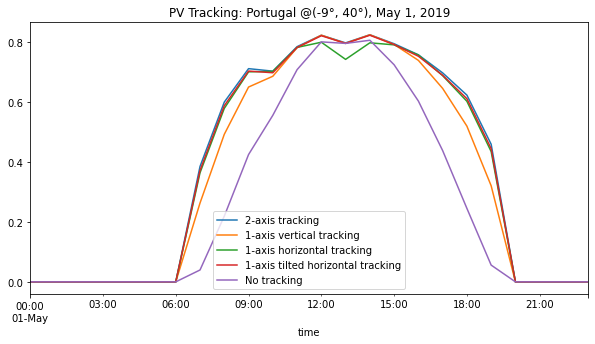

In [12]:
day_profiles = [ds.loc[day, point].squeeze() for ds in data]

df = pd.DataFrame({
    k: v.to_series() for k, v in zip(labels, day_profiles, strict=False)
})
df.plot(figsize=(10, 5))
plt.title("PV Tracking: Portugal @(-9°, 40°), May 1, 2019")

### Yearly Average

Text(0.5, 1.0, 'PV Tracking: Average Capacity Factor per Cell [%]')

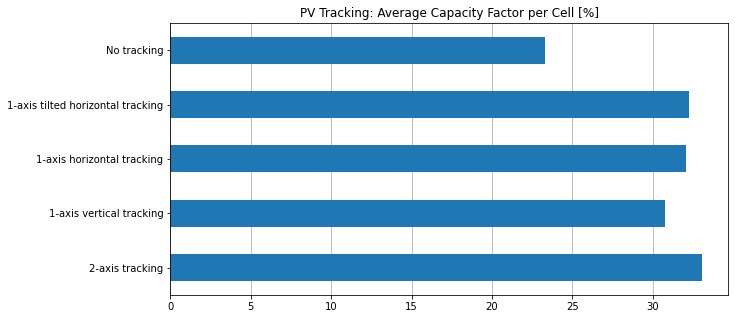

In [13]:
average = [ds.mean("dim_0").mean().item() for ds in data]
df = pd.Series(dict(zip(labels, average, strict=False)))
df.mul(100).plot.barh(figsize=(10, 5), zorder=2)
plt.grid(axis="x", zorder=1)
plt.title("PV Tracking: Average Capacity Factor per Cell [%]")

## Inverter sizing with the DC/AC ratio

Most PV plants install more module (DC) capacity than inverter (AC) capacity. The inverter then clips the output around noon. The argument `dc_ac_ratio` sets this ratio. The output then refers to the AC capacity.

In [14]:
ratios = [1.0, 1.25, 1.5, 1.75, 2.0]


def cf_pv_ratio(dc_ac_ratio):
    return cutout.pv(
        panel="CSi",
        orientation={"slope": 30.0, "azimuth": 180.0},
        shapes=cutout.grid,
        dc_ac_ratio=dc_ac_ratio,
        per_unit=True,
    ).to_pandas()


cf_ac = {r: cf_pv_ratio(r) for r in ratios}

A higher ratio raises the output per unit of AC capacity in the morning and evening, but the inverter clips more energy at noon. The clipping loss is the share of the DC energy that the inverter cannot convert.

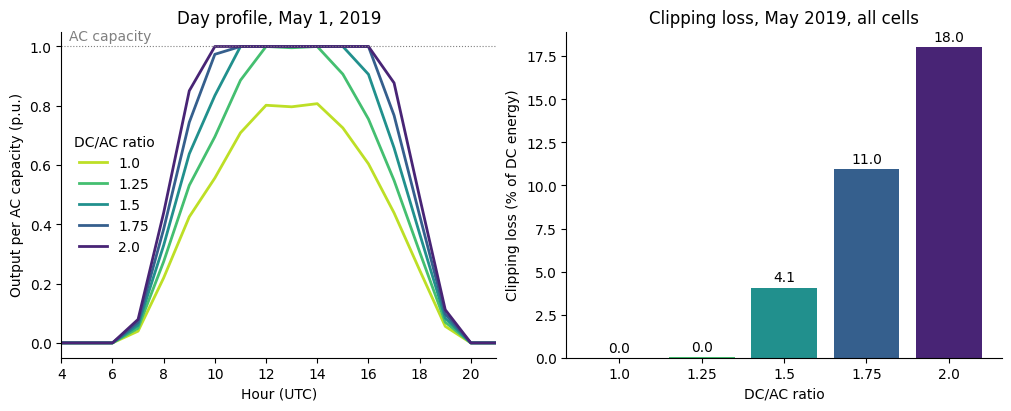

In [15]:
profile = pd.DataFrame({r: cf.loc[day, point].squeeze() for r, cf in cf_ac.items()})
profile.index = profile.index.hour

cf_dc = cf_pv_0axis.to_pandas().mean().mean()
loss = pd.Series({r: 1 - cf.mean().mean() / (r * cf_dc) for r, cf in cf_ac.items()})

colors = plt.get_cmap("viridis_r")([0.1, 0.3, 0.5, 0.7, 0.9])
fig, axs = plt.subplot_mosaic(
    [["profile", "loss"]], figsize=(10, 4), layout="constrained"
)

ax = axs["profile"]
profile.plot(ax=ax, color=colors, lw=2)
ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.text(4.3, 1.01, "AC capacity", color="grey", va="bottom")
ax.legend(title="DC/AC ratio", frameon=False, loc="center left")
ax.set(
    title="Day profile, May 1, 2019",
    xlabel="Hour (UTC)",
    ylabel="Output per AC capacity (p.u.)",
    xlim=(4, 21),
)

ax = axs["loss"]
bars = ax.bar(loss.index.astype(str), loss * 100, color=colors)
ax.bar_label(bars, fmt="%.1f", padding=2)
ax.set(
    title="Clipping loss, May 2019, all cells",
    xlabel="DC/AC ratio",
    ylabel="Clipping loss (% of DC energy)",
)

for ax in axs.values():
    ax.spines[["top", "right"]].set_visible(False)